In [2]:
# Load the libraries needed to explore the river network.

from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx

In [3]:
# Read the NHDPlus connectivity table and flowline attributes.

RAW = Path("../data/raw/nhdplus")

attribute_dir = RAW / "NHDPlusAttribute/NHDPlus04/NHDPlusAttributes"

plusflow = gpd.read_file(attribute_dir / "PlusFlow.dbf")
vaa = gpd.read_file(attribute_dir / "PlusFlowlineVAA.dbf")

plusflow = pd.DataFrame(plusflow.drop(columns="geometry", errors="ignore"))
vaa = pd.DataFrame(vaa.drop(columns="geometry", errors="ignore"))

print("Connectivity records:", len(plusflow))
print("Flowline records:", len(vaa))

display(plusflow.head())
display(vaa.head())

Connectivity records: 144605
Flowline records: 107692


,FROMCOMID,FROMHYDSEQ,FROMLVLPAT,TOCOMID,TOHYDSEQ,TOLVLPAT,NODENUMBER,DELTALEVEL,DIRECTION,GAPDISTKM,HasGeo,TotDASqKM,DivDASqKM
0,1763922,90073479,90029498,1764194,90037496,90029498,90000541,0,709,0.0,Y,45.1593,45.1593
1,0,0,0,1764208,90107443,90029498,90073360,0,712,0.0,Y,0.0000,0.0000
2,1764208,90107443,90029498,1763922,90073479,90029498,90000532,0,709,0.0,Y,34.1982,34.1982
3,1776784,90056880,90047678,1777620,90047678,90047678,90001935,0,709,0.0,Y,16.3341,16.3341
4,1777620,90047678,90047678,1777628,90005554,90004432,90001939,1,709,0.0,Y,16.4214,16.4214


,ComID,Fdate,StreamLeve,StreamOrde,StreamCalc,FromNode,ToNode,Hydroseq,LevelPathI,Pathlength,...,DivEffect,VPUIn,VPUOut,AreaSqKM,TotDASqKM,DivDASqKM,Tidal,TOTMA,WBAreaType,PathTimeMA
0,4799598.0,2011-08-29,4.0,1.0,1.0,90076181.0,90006588.0,90104691.0,90072107.0,18.033,...,0.0,0.0,0.0,0.3708,0.371,0.371,0.0,21.307158,LakePond,64.894333
1,4797518.0,2011-08-29,3.0,1.0,1.0,90075968.0,90006592.0,90104885.0,90104885.0,17.473,...,0.0,0.0,0.0,2.1771,2.177,2.177,0.0,0.125188,NaN,64.865177
2,4797542.0,2011-08-29,3.0,1.0,1.0,90075970.0,90006595.0,90104883.0,90104883.0,18.485,...,0.0,0.0,0.0,4.8915,4.891,4.891,0.0,0.119158,NaN,64.918933
3,4798436.0,2011-08-29,3.0,2.0,2.0,90006899.0,90006902.0,90072031.0,90072031.0,12.174,...,0.0,0.0,0.0,3.6954,14.625,14.625,0.0,0.142159,NaN,0.309131
4,4799656.0,2011-08-29,3.0,1.0,1.0,90076210.0,90006670.0,90104662.0,90047261.0,9.576,...,0.0,0.0,0.0,5.1309,5.131,5.131,0.0,1.913280,LakePond,2.465796


In [4]:
# Check how river reaches are connected using their COMIDs.

print("Connectivity columns:", plusflow.columns.tolist())

edges = plusflow[["FROMCOMID", "TOCOMID"]].copy()

edges = edges.dropna()
edges = edges.astype("int64")

# Remove external or missing connections marked with non-positive IDs.
edges = edges[
    (edges["FROMCOMID"] > 0) &
    (edges["TOCOMID"] > 0)
].drop_duplicates()

print("Valid connections:", len(edges))

display(edges.head(10))

Connectivity columns: ['FROMCOMID', 'FROMHYDSEQ', 'FROMLVLPAT', 'TOCOMID', 'TOHYDSEQ', 'TOLVLPAT', 'NODENUMBER', 'DELTALEVEL', 'DIRECTION', 'GAPDISTKM', 'HasGeo', 'TotDASqKM', 'DivDASqKM']
Valid connections: 109958


,FROMCOMID,TOCOMID
0,1763922,1764194
2,1764208,1763922
3,1776784,1777620
4,1777620,1777628
5,1776714,1776784
7,1777336,1776714
8,1776592,1776600
9,1776572,1776592
11,1776568,1776572
12,1769658,1771946


In [7]:
# Build the directed river graph using the flowline connectivity table.

# Standardize column names
vaa.columns = vaa.columns.str.upper()

# Build the directed graph
G = nx.from_pandas_edgelist(
    edges,
    source="FROMCOMID",
    target="TOCOMID",
    create_using=nx.DiGraph()
)

# Add flowlines that are not included in the connectivity table
flowline_ids = pd.to_numeric(vaa["COMID"], errors="coerce")
flowline_ids = flowline_ids.dropna().astype("int64")

G.add_nodes_from(flowline_ids)

print("Total nodes:", G.number_of_nodes())
print("Total edges:", G.number_of_edges())
print("Directed graph:", G.is_directed())

Total nodes: 107692
Total edges: 109958
Directed graph: True


Nodes with no upstream connections: 34623
Nodes with no downstream connections: 24
Maximum upstream connections: 4
Maximum downstream connections: 3


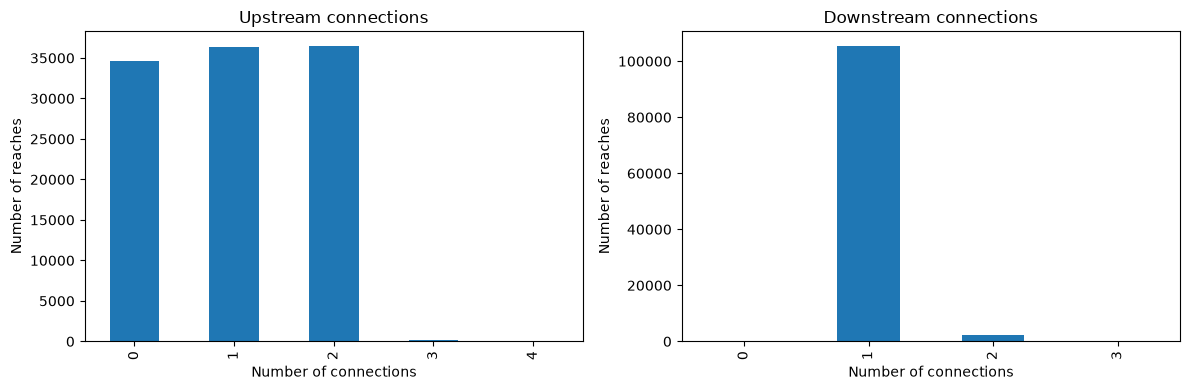

In [8]:
# Check the number of upstream and downstream connections for each reach.

in_degree = pd.Series(dict(G.in_degree()), name="Upstream connections")
out_degree = pd.Series(dict(G.out_degree()), name="Downstream connections")

print("Nodes with no upstream connections:", (in_degree == 0).sum())
print("Nodes with no downstream connections:", (out_degree == 0).sum())
print("Maximum upstream connections:", in_degree.max())
print("Maximum downstream connections:", out_degree.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

in_degree.value_counts().sort_index().loc[lambda x: x.index <= 10].plot.bar(
    ax=axes[0], title="Upstream connections"
)

out_degree.value_counts().sort_index().loc[lambda x: x.index <= 10].plot.bar(
    ax=axes[1], title="Downstream connections"
)

for ax in axes:
    ax.set_xlabel("Number of connections")
    ax.set_ylabel("Number of reaches")

plt.tight_layout()
plt.show()

In [9]:
# Check whether the river network is connected or split into smaller parts.

components = list(nx.weakly_connected_components(G))
component_sizes = sorted((len(c) for c in components), reverse=True)

print("Weakly connected components:", len(component_sizes))
print("Largest component:", component_sizes[0])
print("Smallest component:", component_sizes[-1])
print("Nodes in largest component (%):",
      round(100 * component_sizes[0] / G.number_of_nodes(), 2))

display(pd.DataFrame({
    "Component size": component_sizes[:10]
}))

Weakly connected components: 20
Largest component: 83761
Smallest component: 2
Nodes in largest component (%): 77.78


,Component size
0,83761
1,21301
2,1325
3,490
4,349
5,164
6,150
7,43
8,35
9,16


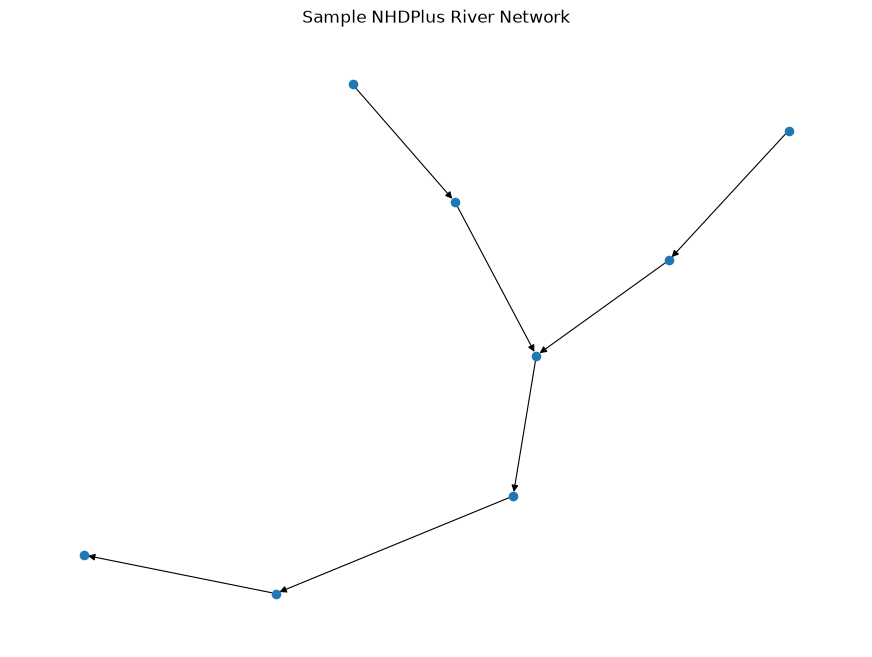

In [13]:
# Plot a small connected section of the river network.

largest_nodes = max(nx.weakly_connected_components(G), key=len)
start_node = next(iter(largest_nodes))

sample_nodes = list(
    nx.bfs_tree(G.to_undirected(as_view=True), start_node, depth_limit=5)
)[:100]

G_sample = G.subgraph(sample_nodes).copy()

plt.figure(figsize=(11, 8))

pos = nx.spring_layout(G_sample, seed=42)

nx.draw_networkx(
    G_sample,
    pos,
    node_size=35,
    arrows=True,
    arrowsize=10,
    with_labels=False,
    width=0.8
)

plt.title("Sample NHDPlus River Network")
plt.axis("off")
plt.show()

In [15]:
# Summarize the main properties of the NHDPlus river graph.

summary = pd.DataFrame({
    "Property": [
        "Nodes",
        "Edges",
        "Weakly connected components",
        "Largest component",
        "Source nodes (in-degree = 0)",
        "Sink nodes (out-degree = 0)",
        "Average in-degree",
        "Average out-degree",
    ],
    "Value": [
        G.number_of_nodes(),
        G.number_of_edges(),
        len(component_sizes),
        component_sizes[0],
        int((in_degree == 0).sum()),
        int((out_degree == 0).sum()),
        round(in_degree.mean(), 3),
        round(out_degree.mean(), 3),
    ]
})

display(summary)

,Property,Value
0,Nodes,107692.000
1,Edges,109958.000
2,Weakly connected components,20.000
3,Largest component,83761.000
4,Source nodes (in-degree = 0),34623.000
5,Sink nodes (out-degree = 0),24.000
6,Average in-degree,1.021
7,Average out-degree,1.021
